# Step 02: Exploratory Data Analysis

Every section asks a question whose answer **changes a decision** in this project.
Try each one yourself first. Hints and spoilers are folded away: click only if you're stuck.

| Section | Decision it feeds |
|---|---|
| 1. Sanity check | Is the data loaded correctly? |
| 2. Duplicates & templates | Step 04 split strategy |
| 3. Text length | Training `max_seq_length`, cost estimate |
| 4. Label balance | How to sample the ~3k tickets for labelling |
| 5. Confusable queues | Final category list (ADR-008) |
| 6. Priority | Priority levels (ADR-008) |
| 7. Entities & placeholders | `entities` field in the schema |
| 8. Agent answers | `suggested_reply` length limit |
| 9. Version effects | Whether to filter by dataset version |

Rules: `SEED = 42` everywhere; read raw examples, not just numbers.

In [39]:
import re

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_colwidth", 200)
SEED = 42

df = pd.read_json("../data/raw/tickets_en.jsonl", lines=True)
df.shape

(23618, 10)

## 1. Sanity check
- What columns and types do we have? Any missing values?
- How many tickets have an empty subject?
- Does every row have a queue, priority and type?

**Why it matters:** every later number is wrong if loading is wrong.

<details><summary>💡 Hint (click to show)</summary>

`df.head()`, `df.dtypes`, `df.isna().sum()`, `(df['subject'] == '').mean()`

</details>

**Your implication:** _..._

In [40]:
# your code
print(df.head())
print(df.dtypes)
print(df.isna().sum())
print((df['subject'] == '').mean())

             id  \
0  93b4a68e11dc   
1  964d7572a41a   
2  e78c11ec658f   
3  6ae212011a35   
4  276bf8d52f6d   

                                                                                                                                                                                                      text  \
0  Account Disruption\n\nDear Customer Support Team,\n\nI am writing to report a significant problem with the centralized account management portal, which currently appears to be offline. This outage...   
1  Query About Smart Home System Integration Features\n\nDear Customer Support Team,\n\nI hope this message reaches you well. I am reaching out to request detailed information about the capabilities ...   
2  Inquiry Regarding Invoice Details\n\nDear Customer Support Team,\n\nI hope this message finds you well. I am reaching out to request clarification about the billing and payment procedures linked t...   
3  Question About Marketing Agency Software Compatibility\n\n

## 2. Duplicates & templates
- The download script removed exact duplicates. Are there still **near-duplicates**?
- Do many tickets start the same way (templates)?
- Are agent answers reused across tickets?

**Why it matters:** if near-copies end up in both train and test, test scores lie (leakage).

<details><summary>💡 Hint (click to show)</summary>

- `df["body"].duplicated().sum()` ignores the subject.
- First lines: `df["body"].str.split("\n").str[0].value_counts().head(10)`
- Normalise before comparing: `.str.lower()`, `.str.replace(r"\s+", " ", regex=True)`, `.str.replace(r"[^\w\s]", "", regex=True)`
- Same idea on `df["answer"]`.

</details>

<details><summary>👀 Spoiler: what Claude already noticed (try first!)</summary>

The script's own output said how many exact duplicates it removed. Check your terminal or the report: it's a surprisingly large share.

</details>

**Your implication:** _..._

In [41]:
# your code
df['body'].duplicated().sum()

df['body'].str.split("\n").str[0].value_counts().head(10)

body
Request for Information on Medical Data Security                                                                                                                                                        2
A critical outage has impacted our data analytics systems, likely due to recent software updates and network disruptions.                                                                               2
Please provide details on securing medical data.                                                                                                                                                        2
Offer insights into digital strategies                                                                                                                                                                  2
Seeking details on securing medical data using OBS Studio 27 and Smart-Home-Kamera applications to maintain confidentiality and comply with regulations.                                   

In [42]:
df['body'] = df['body'].str.lower()
#df['body'] = df['body'].str.replace(r"\s+", " ", regex=True)
df['body'] = df['body'].str.replace(r"[^\w\s]", "", regex=True)
df['body'].str.split("\n").str[0].value_counts().head(10)

body
brand engagement is currently low                                                                                                                              3
facing system instability due to conflicts arising from recent updates                                                                                         2
recent invoices show unexpected billing inconsistencies                                                                                                        2
improve data analytics to optimize investment strategies                                                                                                       2
the saas platform encountered a significant outage                                                                                                             2
the saas platform encountered outages potentially due to server overload or software bugs additional server capacity was added and patches were implemented    2
share insights on digital mar

## 3. Text length
- What does the distribution of ticket length look like (characters and approx tokens)?
- Does length differ by queue?
- Training input = system prompt (~350 tokens) + ticket + JSON output (~300 tokens).
  What `max_seq_length` covers 99% of examples?

**Why it matters:** sequence length drives training memory and speed on the T4.

<details><summary>💡 Hint (click to show)</summary>

- `df["len"] = df["text"].str.len()`; tokens ≈ `len / 4`
- `df["len"].plot.hist(bins=50)`, `df["len"].quantile([0.5, 0.9, 0.99])`
- `df.groupby("queue")["len"].describe()`

</details>

**Your implication:** _..._

In [ ]:
# your code
df['Len'] = df['text'].str.len()

0.50     415.0
0.90     645.3
0.99    1003.0
Name: Len, dtype: float64

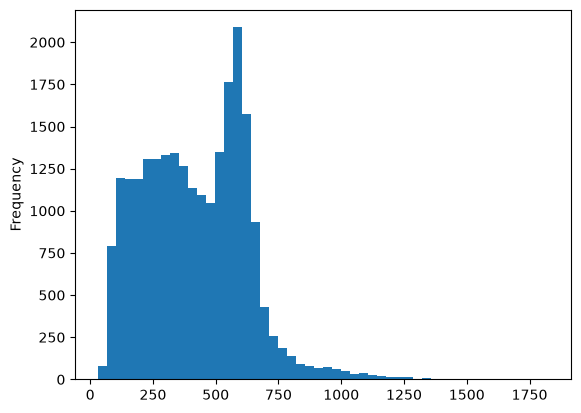

In [50]:
df['Len'].plot.hist(bins=50)
df['Len'].quantile([0.5, 0.9, 0.99])

## 4. Label balance
- How balanced are `queue`, `priority` and `type`?
- If we sample 3,000 tickets randomly, how many would the smallest queue get?
- Random vs stratified vs capped-per-class sampling: which would you pick?

**Why it matters:** a small model needs enough examples of rare classes, but over-sampling distorts reality.

<details><summary>💡 Hint (click to show)</summary>

- `df["queue"].value_counts().plot.barh()`
- Expected count for a class ≈ its share × 3000
- Capped sampling: `df.groupby("queue").sample(n=..., random_state=SEED)` (handle classes smaller than n)

</details>

**Your implication:** _..._

In [56]:
df.head(2)

,id,text,subject,body,answer,queue,priority,type,tags,version,Len
0,93b4a68e11dc,"Account Disruption\n\nDear Customer Support Team,\n\nI am writing to report a significant problem with the centralized account management portal, which currently appears to be offline. This outage...",Account Disruption,dear customer support teamnni am writing to report a significant problem with the centralized account management portal which currently appears to be offline this outage is blocking access to acco...,"Thank you for reaching out, <name>. We are aware of the outage affecting the centralized account management system, and our technical team is actively working to resolve the issue. In the meantime...",Technical Support,high,Incident,"[Account, Disruption, Outage, IT, Tech Support]",51.0,564
1,964d7572a41a,"Query About Smart Home System Integration Features\n\nDear Customer Support Team,\n\nI hope this message reaches you well. I am reaching out to request detailed information about the capabilities ...",Query About Smart Home System Integration Features,dear customer support teamnni hope this message reaches you well i am reaching out to request detailed information about the capabilities of your smart home integration products listed on your web...,"Thank you for your inquiry. Our products support integration with Amazon Alexa, Google Assistant, and Apple HomeKit. Compatibility details can differ depending on the specific item; please let us ...",Returns and Exchanges,medium,Request,"[Product, Feature, Tech Support]",51.0,586


queue
Technical Support                  6835
Product Support                    4395
Customer Service                   3544
IT Support                         2816
Billing and Payments               2407
Returns and Exchanges              1169
Service Outages and Maintenance     934
Sales and Pre-Sales                 719
Human Resources                     459
General Inquiry                     340
Name: count, dtype: int64

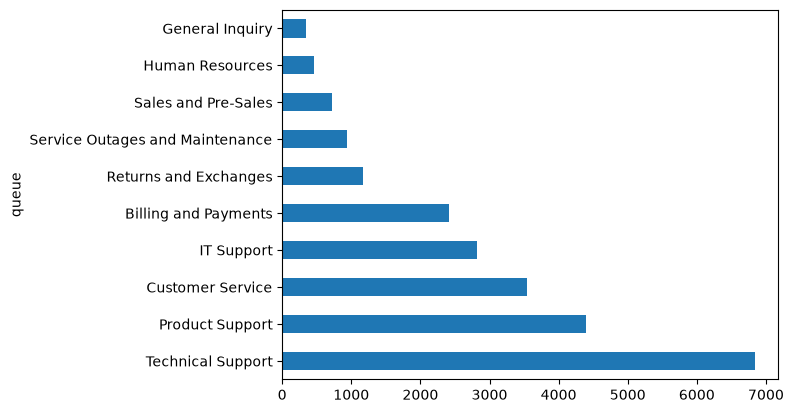

In [61]:
# your code
df['queue'].value_counts().plot.barh()
df['queue'].value_counts()

<Axes: ylabel='priority'>

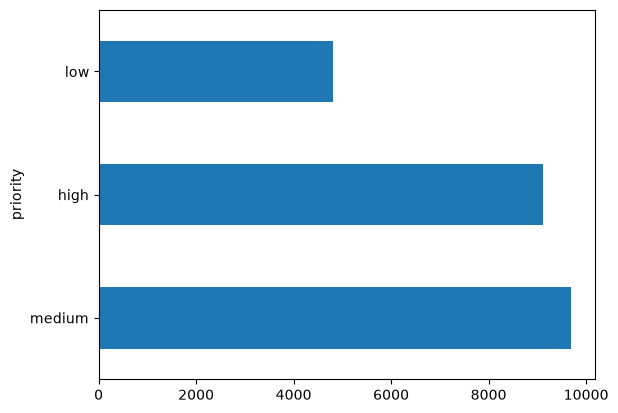

In [62]:
df['priority'].value_counts().plot.barh()

## 5. Confusable queues (most important section)
- Are **Technical Support, IT Support, Product Support and Customer Service** really different?
- Read 5 tickets from each with the label covered. Can *you* guess the queue?
- Which words distinguish each queue?
- How well does a simple non-LLM classifier do, and which queues does it confuse?

**Why it matters:** if a human can't tell two queues apart, a model can't either; they may need merging. The simple classifier is also a **benchmark** the fine-tuned LLM must beat.

<details><summary>💡 Hint (click to show)</summary>

- `df[df.queue == q].sample(5, random_state=SEED)[["text"]]`
- Distinguishing words: `TfidfVectorizer(stop_words="english", min_df=5)`, average rows per queue, top 15 terms.
- Baseline:
  ```python
  from sklearn.feature_extraction.text import TfidfVectorizer
  from sklearn.linear_model import LogisticRegression
  from sklearn.metrics import classification_report, ConfusionMatrixDisplay
  from sklearn.model_selection import train_test_split
  from sklearn.pipeline import make_pipeline
  ```
  `ConfusionMatrixDisplay.from_predictions(y_test, y_pred, xticks_rotation=90)`

</details>

<details><summary>👀 Spoiler: what Claude already noticed (try first!)</summary>

Look at which queues the profile report puts at the top. My guess before seeing the data was that several of the big ones overlap heavily. Is that true?

</details>

**Your implication:** _..._

In [ ]:
# your code

## 6. Priority
- Which priority levels exist in the English data? Do they match our schema's 4 levels?
- How much is priority "explained" by queue alone?
- Read 5 `high` and 5 `low` tickets: is the difference visible in the text?
- How well does the baseline from section 5 predict priority?

**Why it matters:** if priority is only predictable from the queue, the model learns a shortcut instead of reading the ticket.

<details><summary>💡 Hint (click to show)</summary>

- `df["priority"].value_counts()`
- `pd.crosstab(df.queue, df.priority, normalize="index").round(2)`
- Reuse the section 5 pipeline with `y = df["priority"]`

</details>

<details><summary>👀 Spoiler: what Claude already noticed (try first!)</summary>

Compare the priority values you find against `Priority` in `src/triage/schema.py`. They don't line up one-to-one; decide what to do about it.

</details>

**Your implication:** _..._

In [ ]:
# your code

## 7. Entities & placeholders
- Our schema extracts `order_id`, `product`, `account_email`, `amount`. How often does each actually appear?
- Has the data been anonymised? With what placeholder tokens?
- Is there HTML or other junk to clean?
- Are our 4 entity fields the right ones for *this* data? What would you replace them with?

**Why it matters:** if a field is almost always null, the model learns "always null", which is useless.

<details><summary>💡 Hint (click to show)</summary>

- Placeholders: `df["text"].str.findall(r"<[a-z_]+>").explode().value_counts()`
- Regexes to try with `.str.contains(...)`: money `r"\$\s?\d"`, email `r"\b[\w.-]+@[\w.-]+\.\w+\b"`, order `r"(?i)order\s*#?\s*\w*\d"`

</details>

<details><summary>👀 Spoiler: what Claude already noticed (try first!)</summary>

Run the placeholder line from the hint. Notice one token in the list isn't a placeholder at all.

</details>

**Your implication:** _..._

In [ ]:
# your code

## 8. Agent answers
- How long are the agent `answer`s?
- What's their tone and structure? Do they promise things (refunds, timelines)?
- Is `max_length=1200` for `suggested_reply` right? Should the teacher imitate this style?

**Why it matters:** reply length is the biggest driver of output tokens: cost, latency, and training time.

<details><summary>💡 Hint (click to show)</summary>

`df['answer'].str.len().describe()`, then read `df['answer'].sample(5, random_state=SEED)`

</details>

**Your implication:** _..._

In [ ]:
# your code

## 9. Version effects
- Which dataset versions are mixed in, and how many rows are missing a version?
- Do queue / priority distributions or text lengths differ by version?
- Keep all versions, or filter?

**Why it matters:** mixing releases built with different generators can add inconsistent labels.

<details><summary>💡 Hint (click to show)</summary>

- `df["version"].value_counts(dropna=False)`
- `pd.crosstab(df.version.fillna(-1), df.queue, normalize="index").round(2)`

</details>

**Your implication:** _..._

In [ ]:
# your code

## Summary → copy into `docs/steps/02-dataset.md` Findings
1. Near-duplicates:
2. Max sequence length:
3. Sampling strategy:
4. Final categories:
5. Priority levels:
6. Entity fields:
7. Reply length:
8. Versions: